<a href="https://colab.research.google.com/github/KayraOrbay/GROUP37_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CENG313 Project · Group 37

## Problem Definition

The Image Matching Challenge 2025 asks us to group images from each dataset by scene,
identify images that belong to no scene, and reconstruct each scene. For each
registered image, the targets are its scene assignment and camera pose, represented
by a rotation matrix and a translation vector.

The [competition score](https://www.kaggle.com/competitions/image-matching-challenge-2025/overview/evaluation)
combines the mAA of registered camera centers and the scene clustering score using
their harmonic mean per dataset. The final score averages over datasets.


### Setup and data

Run the notebook from the repository root. Install the packages with
`python -m pip install -r requirements.txt` before starting Jupyter.
In Colab, the first code cell clones the repository if needed and installs the packages.

Download `train_labels.csv`, `train_thresholds.csv`, and `sample_submission.csv`
from the [Kaggle Data page](https://www.kaggle.com/competitions/image-matching-challenge-2025/data).
Put the three files in `data/` or select them together when Colab prompts for them.
To run the optional image preprocessing example, also extract the `train/` folder
under `data/`.


In [1]:
from importlib.util import find_spec
from pathlib import Path
import subprocess
import sys

IN_COLAB = find_spec("google") is not None and find_spec("google.colab") is not None
repo_root = Path.cwd()
if IN_COLAB and not (repo_root / "requirements.txt").is_file():
    repo_root = Path("/content/GROUP37_CENG313")
    if not (repo_root / "requirements.txt").is_file():
        subprocess.run([
            "git", "clone", "https://github.com/KayraOrbay/GROUP37_CENG313.git",
            str(repo_root),
        ], check=True)
if IN_COLAB:
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        "-r", str(repo_root / "requirements.txt"),
    ], check=True)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))


In [2]:
from src.data import load_data

data_dir = repo_root / "data"
required_files = ("train_labels.csv", "train_thresholds.csv", "sample_submission.csv")
missing = [name for name in required_files if not (data_dir / name).is_file()]
if IN_COLAB and missing:
    from google.colab import files

    print("Select these Kaggle files:", ", ".join(missing))
    uploaded = files.upload()
    data_dir.mkdir(exist_ok=True)
    for name in missing:
        if name in uploaded:
            (data_dir / name).write_bytes(uploaded[name])
    missing = [name for name in missing if not (data_dir / name).is_file()]
if missing:
    raise FileNotFoundError(f"Missing files in {data_dir}: {', '.join(missing)}")

labels, thresholds, sample_sub = load_data(data_dir)


## Data Overview

In [3]:
import pandas as pd
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 40)

# Data Shape
display(Markdown("### 1. Data shape"))
shape_table = pd.DataFrame(
    {"rows": [df.shape[0] for df in (labels, thresholds, sample_sub)],
     "columns": [df.shape[1] for df in (labels, thresholds, sample_sub)]},
    index=["train_labels", "train_thresholds", "sample_submission"])
display(shape_table)

# Datasets / Scenes
display(Markdown("### 2. Datasets and scenes"))
print("Unique datasets:", labels["dataset"].nunique())
print("Unique (dataset, scene) pairs:", labels.groupby(["dataset", "scene"]).ngroups)

# Data Types
display(Markdown("### 3. Data types (train_labels)"))
types_table = pd.DataFrame({
    "dtype": labels.dtypes.astype(str),
    "non_null": labels.notna().sum(),
    "unique": labels.nunique(),
    "example": labels.iloc[0].astype(str).str.slice(0, 40),
})
display(types_table)

# Missing values
display(Markdown("### 4. Missing values"))
# Missing poses can be real NaN cells or text like "nan;nan;nan"
empty_cells = labels.isna()
nan_text = labels.apply(lambda col: col.astype(str).str.fullmatch(r"(?i)nan(;nan)*")) & ~empty_cells
missing_table = pd.DataFrame({
    "empty (NaN)": empty_cells.sum(),
    "'nan;nan;...' text": nan_text.sum(),
    "total missing": (empty_cells | nan_text).sum(),
    "missing_%": ((empty_cells | nan_text).mean() * 100).round(2),
})
display(missing_table)

# Duplicates
display(Markdown("### 5. Duplicates"))
duplicate_table = pd.DataFrame({"count": [
    labels.duplicated().sum(),
    labels.duplicated(["dataset", "image"]).sum(),
    labels["image"].duplicated().sum(),
]}, index=["fully duplicated rows",
           "duplicated (dataset, image)",
           "same image name in another dataset"])
display(duplicate_table)

# describe()
display(Markdown("### 6. Summary statistics – describe()"))
summary = labels.describe(include="all").T
summary["top"] = summary["top"].astype(str).str.slice(0, 40)
display(summary)


<IPython.core.display.Markdown object>
                   rows  columns
train_labels       1945        5
train_thresholds     30        3
sample_submission  1945        6
<IPython.core.display.Markdown object>
Unique datasets: 13
Unique (dataset, scene) pairs: 34
<IPython.core.display.Markdown object>
                   dtype  ...                                  example
dataset              str  ...                           imc2023_haiper
scene                str  ...                                 fountain
image                str  ...                   fountain_image_116.png
rotation_matrix      str  ...  0.122655949;0.947713775;-0.294608417...
translation_vector   str  ...     0.093771314;-0.803560988;2.062001533

[5 rows x 4 columns]
<IPython.core.display.Markdown object>
                    empty (NaN)  'nan;nan;...' text  total missing  missing_%
dataset                       0                   0              0       0.00
scene                         0                   0   

### Data overview findings

1. Data shape

In the results of the previous code, we see that train_labels.csv has 1945 rows and 5 columns, so we have 1945 training images in total. sample_submission.csv also has 1945 rows. This row count alone does not establish that the images are the same. train_thresholds.csv has 30 rows and when we look at it we can say that each row belongs to one scene.

2. Datasets and scenes

We see that the images come from 13 datasets and 34 (dataset, scene) pairs. Looking at these, we can say that one dataset can include more than one scene. For example, pt_brandenburg_british_buckingham has 3 different scenes. This tells us that the task is not only estimating camera poses; we also need to figure out which images belong to the same scene.

3. Data types

In this table we see that all columns are object which means they are stored as text. This is expected for dataset, scene and image but we notice that rotation_matrix and translation_vector are also text. When we look at the example values, we see that they are numbers separated by ; (9 values for rotation, 3 for translation). So we can say that before doing any numerical analysis we first need to convert these strings into numeric arrays.

4. Missing values

Here we see that dataset, scene and image have no missing values. However, rotation_matrix and translation_vector are missing in 122 rows. When we checked which rows these are we noticed that all of them belong to the outliers scene. From this we can say that these are not really "missing data". These images do not belong to any scene, so they have no camera pose on purpose. Since finding these outlier images is also part of the challenge, we will leave them out only when we calculate pose statistics.

5. Duplicates

In this table we see that there are no fully duplicated rows and no duplicated (dataset, image) pairs, so every image appears only once inside its dataset. However, when we look only at the image names, we see that 8 image names appear in two different datasets. When we checked these rows, we noticed that they come from the dioscuri scene, which is included both in imc2023_heritage and imc2024_dioscuri_baalshamin. Because of this, we can say that the image name alone is not enough to identify an image, so we will use the (dataset, image) pair as a unique key.

6. Summary statistics

The image column contains 1,937 distinct filenames across 1,945 rows, consistent with the eight repeated filenames. On the other hand, dataset and scene are not evenly distributed. The most frequent dataset is pt_brandenburg_british_buckingham with 225 images and the most frequent scene is peach with 200 images. Looking at this, we can say that some scenes have many more images than others, so we need to look at this imbalance in more detail in the EDA part. We also see that the most frequent value in the rotation_matrix and translation_vector columns is the nan pattern, which again points to the outlier images we found in the missing values part.

## Exploratory Data Analysis (EDA)

In this part we explore the camera poses (our target) and how the images are distributed over datasets and scenes. Before the analysis, we parsed rotation_matrix and translation_vector into numbers and calculated some extra values from them, like the rotation angle and the camera position (C = -R^T t). We should note that every scene has its own coordinate system, so the absolute values of different scenes cannot be compared directly.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data import add_pose_features

sns.set_theme(style="whitegrid")
df = add_pose_features(labels)
poses_ok = df[~df["is_outlier_image"]].copy()
print("All images:", len(df), "| with pose:", len(poses_ok), "| outlier images:", df["is_outlier_image"].sum())

All images: 1945 | with pose: 1823 | outlier images: 122


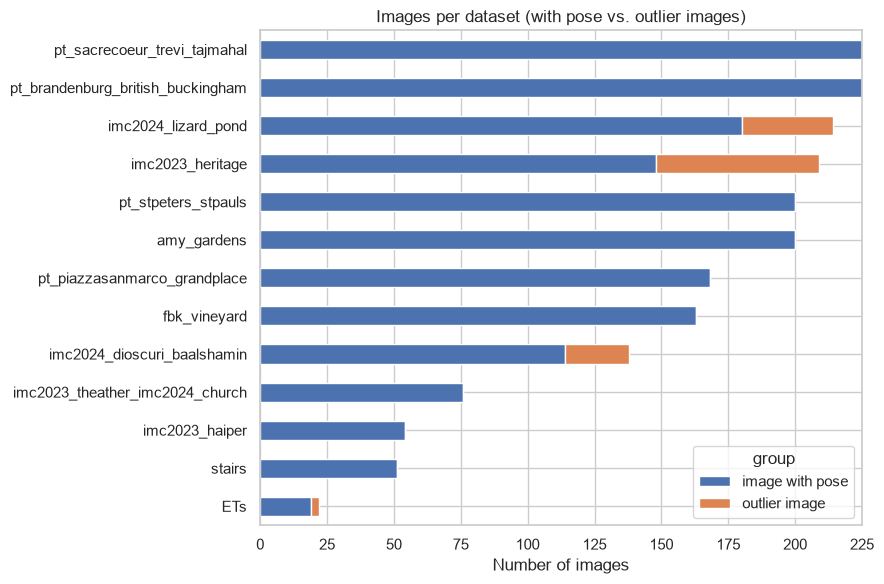

In [5]:
counts = (df.assign(group=np.where(df["is_outlier_image"], "outlier image", "image with pose"))
            .groupby(["dataset", "group"]).size().unstack(fill_value=0))
counts = counts.loc[counts.sum(axis=1).sort_values().index]
ax = counts.plot(kind="barh", stacked=True, figsize=(9, 6), color=["#4C72B0", "#DD8452"][:counts.shape[1]])
ax.set_xlabel("Number of images"); ax.set_ylabel("")
ax.set_title("Images per dataset (with pose vs. outlier images)")
plt.tight_layout(); plt.show()

1. Images per dataset (target balance)

In this plot we see that the number of images is quite different between datasets. The biggest datasets like pt_sacrecoeur_trevi_tajmahal and pt_brandenburg_british_buckingham have 225 images, while ETs has only 22 images. We also notice that outlier images (orange) appear in only 4 datasets: imc2024_lizard_pond, imc2023_heritage, imc2024_dioscuri_baalshamin and ETs. imc2023_heritage has the largest share of outliers, with 61 of its 209 images (29.2%), which means almost one third of its images do not belong to any scene. Looking at this, we can say that our model should not assume every image belongs to a scene, because in some datasets a big part of the images are outliers that we need to reject.

count     30.0
mean      60.8
std       39.3
min        9.0
25%       28.5
50%       66.5
75%       75.0
max      200.0
dtype: float64


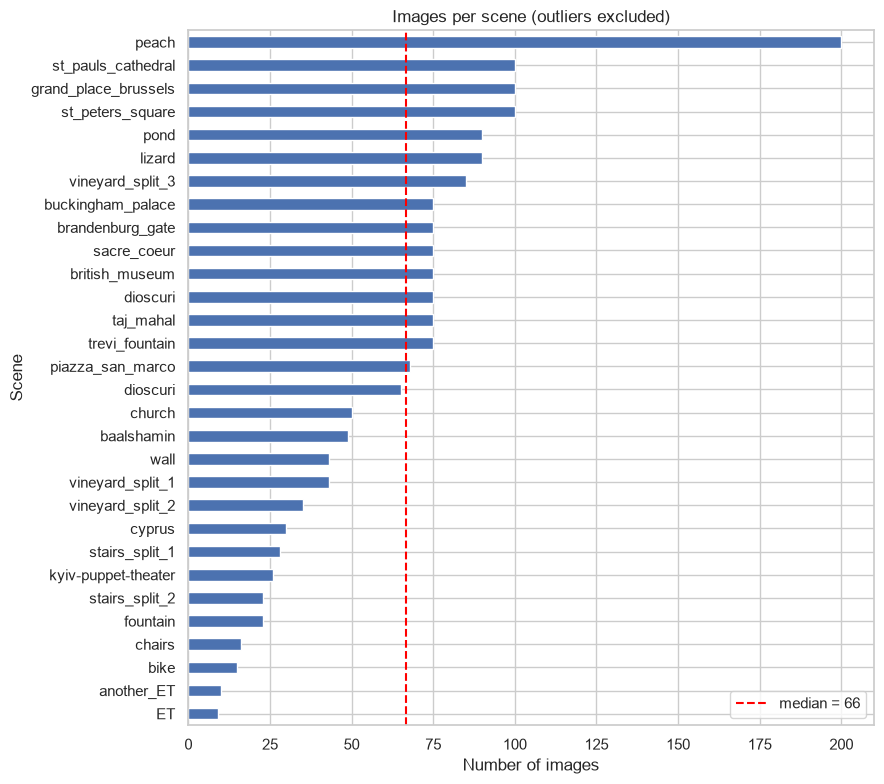

In [6]:
scene_counts = poses_ok.groupby(["dataset", "scene"]).size().sort_values()
fig, ax = plt.subplots(figsize=(9, 8))
scene_counts.plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_yticklabels([s for _, s in scene_counts.index])
ax.axvline(scene_counts.median(), color="red", ls="--", label=f"median = {scene_counts.median():.0f}")
ax.set_xlabel("Number of images"); ax.set_ylabel("Scene"); ax.legend()
ax.set_title("Images per scene (outliers excluded)")
plt.tight_layout(); plt.show()
print(scene_counts.describe().round(1))

2. Images per scene (target balance)

Here we see that there are 30 scenes and the median number of images per scene is 66. The scenes are not balanced: peach has 200 images, which is much more than the others, while ET and another_ET have only 9 and 10 images. All of the phototourism scenes (st_pauls_cathedral, grand_place_brussels, st_peters_square etc.) are above the median, while the imc2023_haiper scenes (fountain, chairs, bike) and ETs are at the bottom. We also see dioscuri twice because the same scene exists in two different datasets. From this we can say that small scenes will be harder to reconstruct since there are fewer images to match. Also, since mAA is calculated separately for each scene, every single image in a small scene has a bigger effect on that scene's score than an image in a big scene.

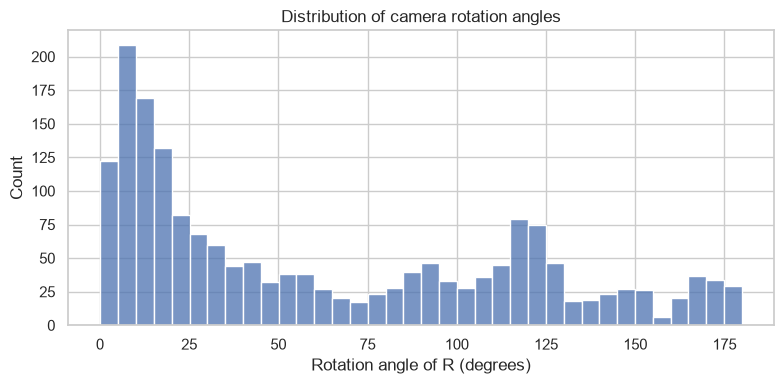

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(poses_ok["rot_angle_deg"], bins=36, ax=ax)
ax.set_xlabel("Rotation angle of R (degrees)"); ax.set_title("Distribution of camera rotation angles")
plt.tight_layout(); plt.show()

3. Distribution of camera rotation angles (distribution)

In this histogram we see that the highest bar is between about 5 and 10 degrees, and around 40% of the cameras have a rotation angle below 25 degrees. This means a large group of cameras have an orientation close to the reference coordinate system of their scene. However, the distribution has a long tail and a second peak around 115-125 degrees, and some cameras go up to 180 degrees. Looking at this, we can say that the data includes photos taken from very different, even opposite, viewing directions. Matching keypoints between these images will be harder, so our method needs features that are robust to large viewpoint changes.

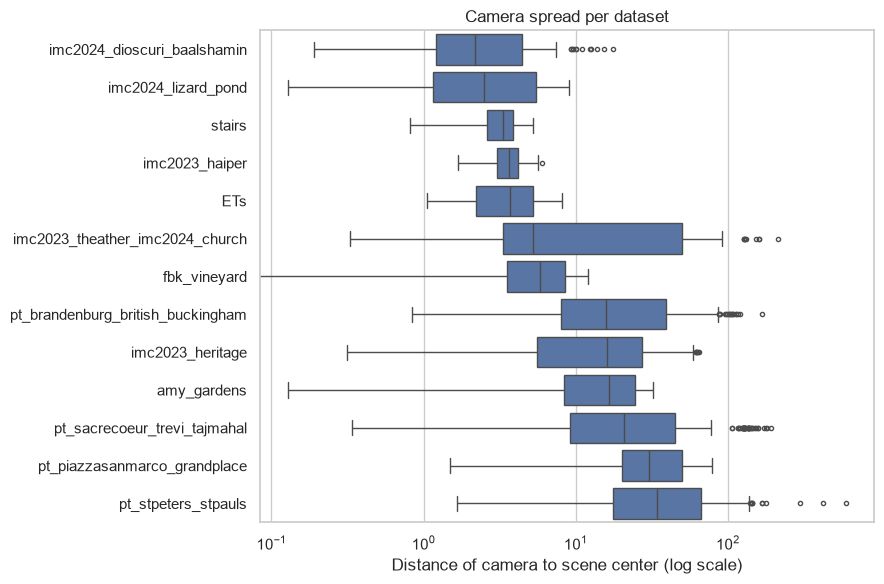

In [8]:
order = poses_ok.groupby("dataset")["dist_to_center"].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=poses_ok, y="dataset", x="dist_to_center", order=order, ax=ax, color="#4C72B0", fliersize=3)
ax.set_xscale("log")
ax.set_xlabel("Distance of camera to scene center (log scale)"); ax.set_ylabel("")
ax.set_title("Camera spread per dataset")
plt.tight_layout(); plt.show()

4. Camera spread per dataset (distribution and outliers)

In this boxplot we see how far the cameras are from the center of their scene (in log scale). The values change a lot between datasets: in imc2024_dioscuri_baalshamin, imc2024_lizard_pond, stairs, imc2023_haiper and ETs the median distance is only between 2.2 and 3.7 units, while in the phototourism datasets (pt_...) the median is between 15.8 and 34.1 units and some cameras go above 100. imc2023_theather_imc2024_church has a very wide box, which we think is because its two scenes have very different scales. We also notice that many of the outlier points (small circles) are in the phototourism datasets. From this we can say that the scale of each dataset is very different, and this is probably why the competition uses different thresholds for each dataset in train_thresholds.csv. The outlier points in phototourism probably come from tourist photos taken from much further away than the others.

In [9]:
def iqr_flags(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return (s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))

poses_ok["far_camera"] = poses_ok.groupby(["dataset", "scene"])["dist_to_center"].transform(iqr_flags)
outlier_summary = (poses_ok.groupby(["dataset", "scene"])
                   .agg(images=("image", "size"), far_cameras=("far_camera", "sum"))
                   .assign(far_pct=lambda d: (100 * d["far_cameras"] / d["images"]).round(1))
                   .sort_values("far_pct", ascending=False))
display(outlier_summary.head(10))
print("Total far cameras (IQR rule):", int(poses_ok["far_camera"].sum()), "of", len(poses_ok))
print("Rotation check -> det(R) range:", round(poses_ok["det_R"].min(), 4), "to", round(poses_ok["det_R"].max(), 4),
      "| max orthogonality error:", round(poses_ok["orth_err"].max(), 6))

                                                      images  ...  far_pct
dataset                           scene                       ...         
imc2023_haiper                    fountain                23  ...     17.4
pt_sacrecoeur_trevi_tajmahal      sacre_coeur             75  ...     10.7
imc2024_dioscuri_baalshamin       baalshamin              49  ...     10.2
ETs                               another_ET              10  ...     10.0
pt_stpeters_stpauls               st_pauls_cathedral     100  ...      9.0
pt_piazzasanmarco_grandplace      piazza_san_marco        68  ...      8.8
pt_brandenburg_british_buckingham brandenburg_gate        75  ...      8.0
imc2024_dioscuri_baalshamin       dioscuri                65  ...      7.7
imc2023_haiper                    chairs                  16  ...      6.2
pt_stpeters_stpauls               st_peters_square       100  ...      3.0

[10 rows x 3 columns]
Total far cameras (IQR rule): 49 of 1823
Rotation check -> det(R) range: 1.0 

5. Outlier cameras (outliers)

To find unusual cameras, we used the IQR rule on the distance to the scene center, separately for each scene. In the table we see that only 49 of 1823 cameras (around 2.7%) are flagged as far cameras. The highest share is in fountain (4 of 23 cameras, 17.4%), followed by sacre_coeur and baalshamin with around 10%. We also checked if all rotation matrices are valid (det(R) = 1 and R R^T = I), and we see that det(R) is 1.0 for every camera and the largest orthogonality error is only 6e-06, so all rotation matrices are valid. Looking at this, we can say that these far cameras are not data errors but real photos taken from a bigger distance. That is why we decided to keep them, but we expect these images to be harder to register because they share fewer keypoints with the others.

Spearman correlation: 0.62


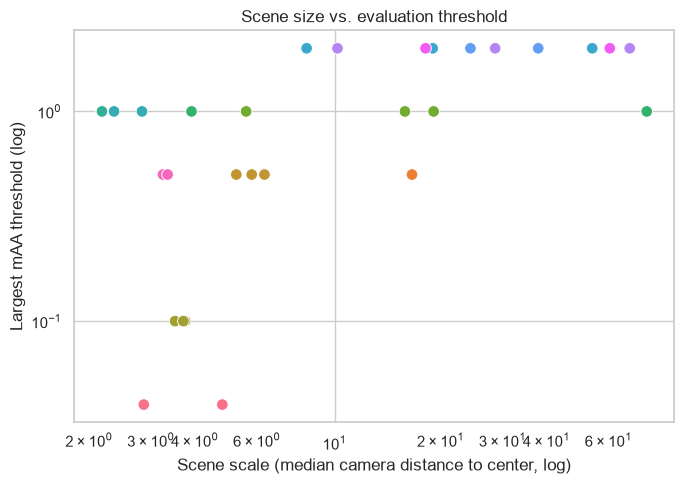

In [10]:
thr = thresholds.copy()
thr_vals = thr["thresholds"].str.split(";").apply(lambda v: [float(x) for x in v])
thr["thr_max"] = thr_vals.apply(max)
scale = poses_ok.groupby(["dataset", "scene"])["dist_to_center"].median().rename("scene_scale").reset_index()
rel = scale.merge(thr, on=["dataset", "scene"], how="inner")
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=rel, x="scene_scale", y="thr_max", hue="dataset", s=70, ax=ax, legend=False)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Scene scale (median camera distance to center, log)")
ax.set_ylabel("Largest mAA threshold (log)")
ax.set_title("Scene size vs. evaluation threshold")
plt.tight_layout(); plt.show()
print("Spearman correlation:", rel["scene_scale"].corr(rel["thr_max"], method="spearman").round(2))

6. Scene size vs. evaluation threshold (relationship with the target)

In this plot we compare the size of each scene (median camera distance to the center) with the largest mAA threshold of that scene. We see a positive relationship, and the Spearman correlation is 0.62. Most of the scenes with a scale above 10 (mostly phototourism scenes) have the largest threshold of 2.0, while the smallest scenes have much smaller thresholds like 0.1 or 0.04. We also notice that points with the same color, which belong to the same dataset, are on the same horizontal line, so the thresholds are chosen per dataset and not per scene. Looking at this, we can say that the competition uses bigger thresholds for bigger scenes. This means the same pose error (for example 1 unit) is a small mistake in a big scene but a big mistake in a small scene. Because of this, we should not compare raw pose errors between scenes and should always evaluate them with their own thresholds.

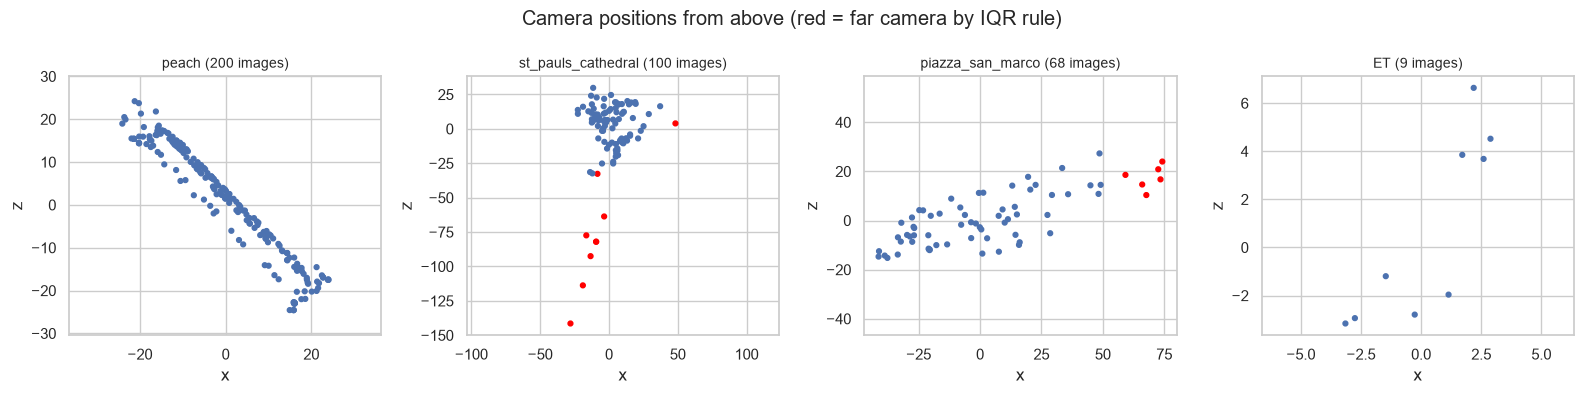

In [11]:
examples = scene_counts.index[[-1, -2, len(scene_counts) // 2, 0]]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (ds, sc) in zip(axes, examples):
    s = poses_ok[(poses_ok["dataset"] == ds) & (poses_ok["scene"] == sc)]
    ax.scatter(s["cx"], s["cz"], s=12, c=s["far_camera"].map({True: "red", False: "#4C72B0"}))
    ax.set_title(f"{sc} ({len(s)} images)", fontsize=10); ax.set_xlabel("x"); ax.set_ylabel("z")
    ax.set_aspect("equal", adjustable="datalim")
fig.suptitle("Camera positions from above (red = far camera by IQR rule)")
plt.tight_layout(); plt.show()

7. Camera positions in example scenes (relationship with the target)

Here we see the camera positions from above for four scenes with different sizes. In peach (200 images) the cameras are placed almost on a straight line, which looks like the photographer walked along a path while taking photos. In st_pauls_cathedral most cameras are close together around the center, but the red far cameras go down to around -140 on the z axis, so some photos were taken from much further away. In piazza_san_marco the cameras are spread over a wide area and the far cameras are all on the right side of the square. ET has only 9 cameras that are far from each other, so there are big gaps between the viewpoints. From this we can say that every scene has a different camera layout: scenes like peach, where neighboring images are very close to each other, should be easier to match, while scenes with few and widely spread cameras like ET will be harder for our model.

## Preprocessing

1. Cleaning

In the data overview we saw that rotation_matrix and translation_vector are stored as text, so we converted them into a 3x3 rotation matrix and a length-3 translation vector for every image. We also saw that the image name alone is not unique, so we created a key column from the (dataset, image) pair and we checked that this key is unique. Since there are no duplicated rows and all rotation matrices passed the validity check in the EDA, we did not need to remove any rows.

2. Imputation

We did not use any imputation. The only missing values are the poses of the 122 outlier images and these images do not belong to any scene, so they do not have a real camera pose. If we filled them with something like the mean pose, we would create cameras that do not exist. Instead, we kept these rows and marked them with an is_outlier_image flag because detecting them is part of the task.

3. Encoding

The submission file expects every image to be assigned to a cluster, like cluster0, cluster1. Because of this, we encoded the scenes inside each dataset as integers (0, 1, 2, ...) and gave the outlier images the value -1. We encoded them separately for each dataset, because scenes in different datasets are not related to each other.

4. Scaling

We did not scale the rotation and translation values, because the mAA thresholds in train_thresholds.csv are defined in the original units of each scene, so scaling them would make the evaluation wrong. For the images, we convert them to grayscale and resize them so that the longest side is 1024 pixels. We do this because keypoint detectors like SIFT work on grayscale images and smaller images make matching much faster. We also keep the scale factor, so we can move the keypoints back to the original image size when we estimate the poses. For example, one of our images was 1440 × 1920 pixels (width × height) and after preprocessing it became 768 × 1024 with a scale factor of 0.533.

In [12]:
from src.data import preprocess_labels, load_image

clean = preprocess_labels(labels)

# 1) Before / after
print("Before:", labels.shape, "| After:", clean.shape)
display(clean.head())

# 2) Outlier images are kept and flagged, not dropped or imputed
print("Outlier images kept:", int(clean["is_outlier_image"].sum()))

# 3) Scene encoding inside each dataset
display(clean.drop_duplicates(["dataset", "scene"])
             .sort_values(["dataset", "scene_id"])[["dataset", "scene", "scene_id"]])

# 4) Unique key check
print("Is key unique?", clean["key"].is_unique)

# 5) Image preprocessing example (only if the images are downloaded)
img_dir = data_dir / "train"
example = img_dir / clean.loc[0, "dataset"] / clean.loc[0, "image"]
if example.exists():
    import cv2
    original = cv2.imread(str(example))
    small, scale = load_image(example, max_size=1024)
    print("Original size (height, width):", original.shape[:2], "| after preprocessing:", small.shape, "| scale:", round(scale, 3))
else:
    print("Images not found in", img_dir, "- skipping the image example.")

Before: (1945, 5) | After: (1945, 8)
                                     key  ...                                 t
0  imc2023_haiper/fountain_image_116.png  ...   [0.093771, -0.803561, 2.062002]
1  imc2023_haiper/fountain_image_108.png  ...   [0.358947, -0.797558, 1.910907]
2  imc2023_haiper/fountain_image_101.png  ...   [0.146922, -0.981393, 2.009003]
3  imc2023_haiper/fountain_image_082.png  ...   [0.206414, -1.174321, 3.667168]
4  imc2023_haiper/fountain_image_071.png  ...  [-0.015141, -1.334052, 3.488937]

[5 rows x 8 columns]
Outlier images kept: 122
                                dataset                 scene  scene_id
1872                                ETs              outliers        -1
1875                                ETs                    ET         0
1884                                ETs            another_ET         1
1509                        amy_gardens                 peach         0
1829                       fbk_vineyard      vineyard_split_1         0
1709

## Baseline pilot: relative pose on Fountain

We use four images from the labeled Fountain scene to test the pairwise geometry.
The pipeline extracts SIFT descriptors, keeps matches with a nearest-neighbor
distance ratio below 0.75, fits an essential matrix with RANSAC, and recovers the
relative rotation and translation direction. We approximate the focal length
using the longest resized image dimension and place the principal point at the
image center. Translation has unknown scale, and the scene label is used only
to select the pilot images.

The table reports feature matches and pose inliers for each pair.


In [13]:
from itertools import combinations

import cv2
from src.models import estimate_relative_pose, extract_features

dataset = "imc2023_haiper"
scene = labels.loc[(labels["dataset"] == dataset) & (labels["scene"] == "fountain")]
image_dir = data_dir / "train" / dataset
paths = [image_dir / name for name in sorted(scene["image"])[:4]]

if all(path.is_file() for path in paths):
    cv2.setRNGSeed(42)
    features = {path: extract_features(path) for path in paths}
    pair_results = []
    for first, second in combinations(paths, 2):
        pose = estimate_relative_pose(features[first], features[second])
        pair_results.append({
            "First image": first.name,
            "Second image": second.name,
            "Matches": pose.matches if pose is not None else None,
            "Pose inliers": pose.inliers if pose is not None else None,
            "Pose recovered": pose is not None,
        })
    print(pd.DataFrame(pair_results).to_string(index=False))
else:
    print("Extract the training images under data/train/ to run the pilot.")


           First image           Second image  Matches  Pose inliers  Pose recovered
fountain_image_000.png fountain_image_007.png      226           158            True
fountain_image_000.png fountain_image_012.png       75            38            True
fountain_image_000.png fountain_image_025.png       32            17            True
fountain_image_007.png fountain_image_012.png      315           172            True
fountain_image_007.png fountain_image_025.png       34            18            True
fountain_image_012.png fountain_image_025.png       62            38            True


## Baseline validation

We hold out 20% of the images with seed 42, stratified by dataset and scene.
This baseline is training-free. During inference it receives only the held-out
image names grouped by dataset. It compares image pairs using the pilot method.
Pairs with at least 15 pose inliers and a 25% inlier ratio form a graph.
Connected components become predicted scenes, and isolated images become
outliers. Inside each component we compose poses along a maximum-weight
spanning tree, treating each translation direction as a unit-length step.
This simplifying assumption can distort camera distances.

The local score follows the [IMC 2025 evaluation rules](https://www.kaggle.com/competitions/image-matching-challenge-2025/overview/evaluation).
It aligns predicted camera centers to ground truth, measures pose mAA and
clustering precision, and averages their per-dataset harmonic means.
The local implementation uses an SVD similarity fit and the unmasked scoring
settings documented in the [published reference implementation](https://huggingface.co/stpete2/imc25_utils/commit/04c9578be6c90de62348f509d5cef22700024afa).
The held-out result is a local validation score.


In [14]:
from src.evaluation import score_validation, split_validation
from src.models import predict_dataset

development, held_out = split_validation(labels, seed=42)
print(f"Development images: {len(development)} | Held-out images: {len(held_out)}")
train_dir = data_dir / "train"
if train_dir.is_dir():
    cv2.setRNGSeed(42)
    predictions = []
    for dataset, images in held_out[["dataset", "image"]].groupby("dataset"):
        prediction = predict_dataset(images["image"], train_dir / dataset)
        predictions.append(prediction.assign(dataset=dataset))
    predictions = pd.concat(predictions, ignore_index=True)
    scores = score_validation(held_out, predictions, thresholds)
    print(scores.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
    print(f"Mean held-out score: {scores['Score'].mean():.4f}")
else:
    print("Extract the training images under data/train/ to run validation.")


Development images: 1556 | Held-out images: 389
                          Dataset  Pose mAA  Clustering precision  Score
                              ETs    0.0000                1.0000 0.0000
                      amy_gardens    0.0203                1.0000 0.0397
                     fbk_vineyard    0.0000                1.0000 0.0000
                   imc2023_haiper    0.0000                0.3333 0.0000
                 imc2023_heritage    0.0357                0.3333 0.0645
  imc2023_theather_imc2024_church    0.0000                0.5000 0.0000
      imc2024_dioscuri_baalshamin    0.0000                0.4091 0.0000
              imc2024_lizard_pond    0.0083                0.7647 0.0165
pt_brandenburg_british_buckingham    0.0208                0.3333 0.0392
     pt_piazzasanmarco_grandplace    0.0093                0.5000 0.0182
     pt_sacrecoeur_trevi_tajmahal    0.0139                0.3333 0.0267
              pt_stpeters_stpauls    0.0074                0.5000 0.0145
   

## Kaggle Submission

We submitted [Version 3](https://www.kaggle.com/code/kayraorbay/notebookf452731e5f?scriptVersionId=369238802)
as a late entry to the Image Matching Challenge 2025 on 13 November 2026.
At the last verified check, Kaggle was still running the notebook and the
public and private score fields were empty.
[Competition submission record](https://www.kaggle.com/competitions/image-matching-challenge-2025/submissions)

The available result is a **local held-out score of 0.0169 (1.69%)**
on 389 images. The winning team reported 52.64 on the public leaderboard.
The gap is about 51 percentage points for context. The two scores use
different test images, so the gap cannot isolate the effect of the method.
[Winning team's published results](https://www.kaggle.com/competitions/image-matching-challenge-2025/writeups/ns64-1st-place-solution)


## Conclusion

The training data contains 1,945 images across 13 datasets. We retained the
122 outlier images and flagged them during preprocessing. Scene sizes vary
from 9 to 200 images, which affects how many overlapping views are available.

The Fountain pilot recovered relative poses for all six image pairs. Across
the held-out datasets, however, the baseline scored 1.69%. Pairwise pose
recovery establishes that the images have geometrically consistent matches.
Chaining those poses with unit-length translations can distort camera
distances. False match edges can also join separate scenes.

For Assignment 2, we would use verified matches to build multi-view tracks
and refine camera poses jointly with bundle adjustment. We would compare
pose mAA and clustering precision on the same held-out split and use
candidate-pair retrieval to reduce the cost of exhaustive matching.
